# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:** Abdul Qudoos
- **Roll No:** 023-24-0233
- **Section:** G
- **Date:** 16-Nov-2026

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

RS = 42                     
np.random.seed(RS)
iris = load_iris()
print("Iris dataset shape:", iris.data.shape)
print("Class names:", iris.target_names.tolist())

Iris dataset shape: (150, 4)
Class names: ['setosa', 'versicolor', 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [ ]:
# Task 1.1:
def weighted_sum(w, x, b):
    # net input z = w . x + b
    return np.dot(w, x) + b

def step_function(z):
    
    return int(z >= 0)

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))


print("Slide 16 -> predict([0.6, 0.8], [2, 3], -2) =", predict([0.6, 0.8], [2, 3], -2))


w17, b17 = [1, -0.5], 0.5
samples = [[1, 1], [2, 1], [0, 3]]
targets = [1, 1, 0]
print("\nSlide 17 check:")
for s, t in zip(samples, targets):
    z = weighted_sum(w17, s, b17)
    out = predict(w17, s, b17)
    status = "OK" if out == t else "WRONG"
    print(f"  input {s}:  z = {z:5.2f}  ->  y_hat = {out}  (expected {t})  {status}")

Slide 16 -> predict([0.6, 0.8], [2, 3], -2) = 1

Slide 17 check:
  input [1, 1]:  z =  1.00  ->  y_hat = 1  (expected 1)  OK
  input [2, 1]:  z =  2.00  ->  y_hat = 1  (expected 1)  OK
  input [0, 3]:  z = -1.00  ->  y_hat = 0  (expected 0)  OK


**Interpretation:** All the outputs match the slides, so the three functions work. For slide 16 we get z = 1.2 + 2.4 − 2 = 1.6, which is positive, so the neuron fires. In slide 17 the input [0, 3] is the only one that gives 0, because its second weight is negative (−0.5), so x₂ = 3 drags z down to −1.

### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [ ]:
# Task 1.2: 
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])

weights = np.array([0.2, -0.1])
bias = 0.0
lr = 0.1
errors = 0

print("row | x      | y | z     | y_hat | e  | updated w     | updated b")
print("-" * 68)
for row, (x, target) in enumerate(zip(X_and, y_and), start=1):
    z = weighted_sum(weights, x, bias)
    y_hat = step_function(z)
    e = target - y_hat
    weights = weights + lr * e * x     
    bias = bias + lr * e               
    errors += int(e != 0)
    print(f" {row}  | {x} | {target} | {z:5.2f} |   {y_hat}   | {e:2d} | {np.round(weights, 2)}  | {bias:.2f}")

print("\nw after one epoch:", np.round(weights, 2), "| b after one epoch:", round(bias, 2))
print("Mistakes in this epoch:", errors)
if errors == 0:
    print("Converged!")
else:
    print("Keep training.")

row | x      | y | z     | y_hat | e  | updated w     | updated b
--------------------------------------------------------------------
 1  | [0 0] | 0 |  0.00 |   1   | -1 | [ 0.2 -0.1]  | -0.10
 2  | [0 1] | 0 | -0.20 |   0   |  0 | [ 0.2 -0.1]  | -0.10
 3  | [1 0] | 0 |  0.10 |   1   | -1 | [ 0.1 -0.1]  | -0.20
 4  | [1 1] | 1 | -0.20 |   0   |  1 | [0.2 0. ]  | -0.10

w after one epoch: [0.2 0. ] | b after one epoch: -0.1
Mistakes in this epoch: 3
Keep training.


**Interpretation:** After one pass over the AND data the perceptron got 3 of the 4 rows wrong, so it prints "Keep training." The first row is wrong only because z = 0 counts as firing, and in row 3 just w₁ moves since x₂ is 0 (multiplying by 0 means no change). The last row pushed everything back up, so the weights are still jumping around (w = [0.2, 0.0], b = −0.1) and one epoch is clearly not enough.

## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [ ]:
# Task 2.1:
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    w = np.zeros(X.shape[1])
    b = 0.0
    history = []                     
    for ep in range(max_epochs):
        wrong = 0
        for xi, target in zip(X, y):
            err = target - predict(w, xi, b)
            if err != 0:             
                w += eta * err * xi
                b += eta * err
                wrong += 1
        history.append(wrong)
        if wrong == 0:                
            break
    return w, b, history

X_or = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_or = np.array([0, 1, 1, 1])

w_or, b_or, hist_or = train_perceptron(X_or, y_or)
print("OR gate result")
print("  final w :", w_or)
print("  final b :", round(b_or, 2))
print("  mistakes per epoch:", hist_or)
print("  epochs until convergence:", len(hist_or))

OR gate result
  final w : [0.1 0.1]
  final b : -0.1
  mistakes per epoch: [2, 2, 1, 0]
  epochs until convergence: 4


**Interpretation:** The OR gate was learned in 4 epochs with w = [0.1, 0.1] and b = −0.1. Both weights came out equal, which fits OR because it doesn't matter which input is on. Only (0, 0) gets a negative score (−0.1); the rest get 0 or more, so they are classified as 1. Since OR is linearly separable it was expected to converge, and it did.

### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

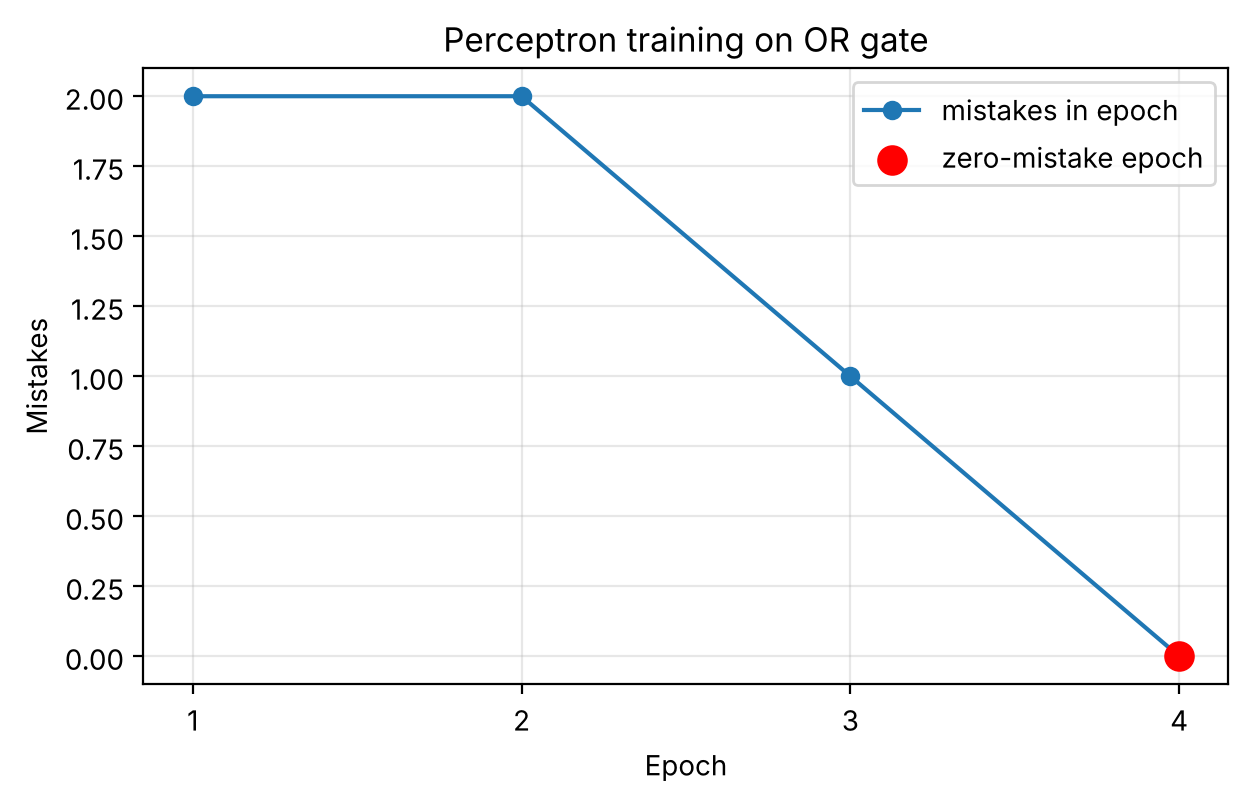

In [ ]:
# Task 2.2:
ep_axis = np.arange(1, len(hist_or) + 1)

plt.figure(figsize=(7, 4))
plt.plot(ep_axis, hist_or, 'o-', color='tab:blue', label='mistakes in epoch')
plt.scatter(ep_axis[-1], hist_or[-1], color='red', s=100, zorder=3, label='zero-mistake epoch')
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.xticks(ep_axis)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Interpretation:** The mistakes go 2 → 2 → 1 → 0, so overall the trend is downward and training ends at the red dot in epoch 4. It stays flat between epochs 1 and 2 because fixing one point can mess up another one, but it still gets there.

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

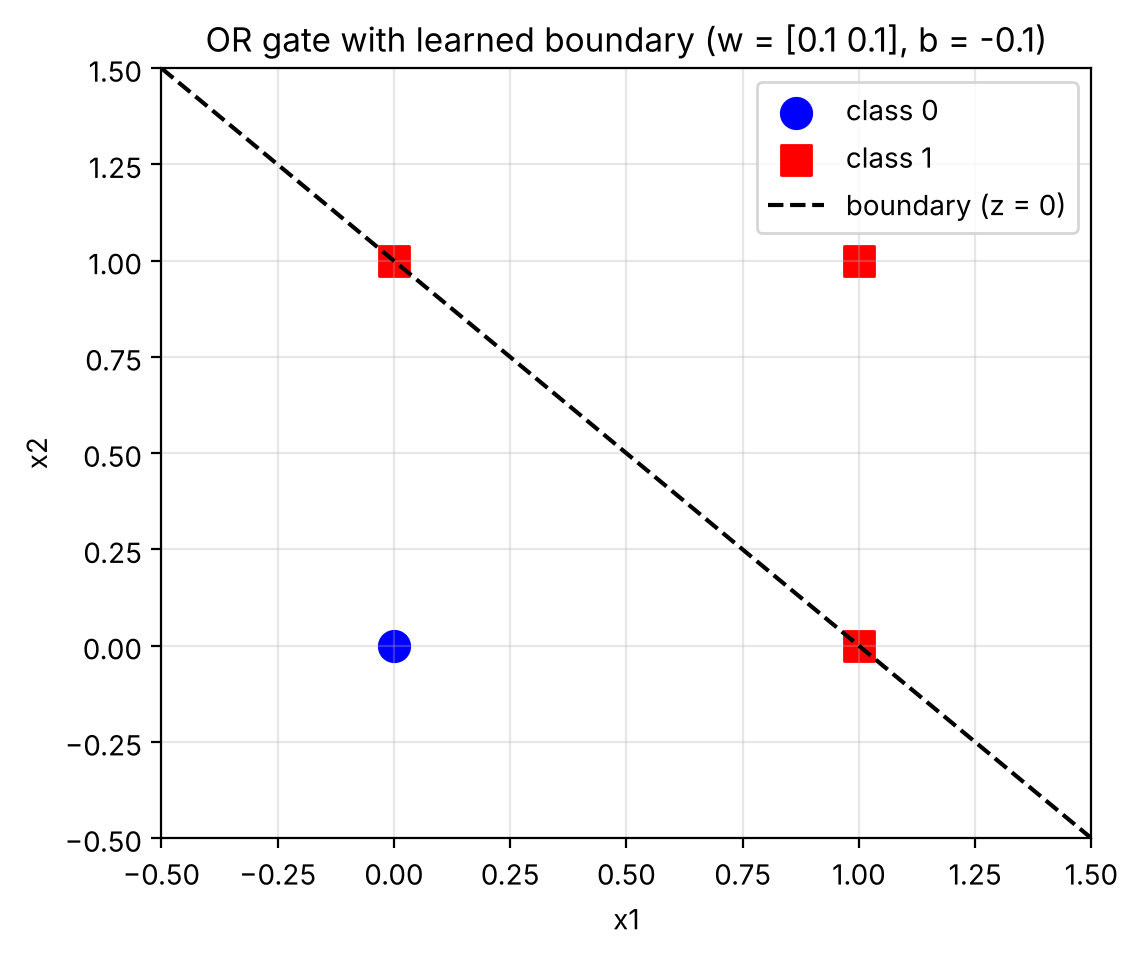

In [ ]:
# Task 3.1: 
def plot_boundary(ax, w, b, x1=np.linspace(-0.5, 1.5, 100), label='boundary (z = 0)'):
    # z = 0  ->  x2 = -(w1/w2) * x1 - b/w2
    if w[1] != 0:
        ax.plot(x1, -(w[0] / w[1]) * x1 - b / w[1], 'k--', label=label)
    elif w[0] != 0:
        # w2 = 0 means the line is vertical at x1 = -b/w1
        ax.axvline(-b / w[0], color='k', linestyle='--', label=label)
    else:
        print("Both weights are zero, nothing to draw.")

def scatter_classes(ax, X, y):
    ax.scatter(X[y == 0, 0], X[y == 0, 1], color='blue', marker='o', s=120, label='class 0')
    ax.scatter(X[y == 1, 0], X[y == 1, 1], color='red', marker='s', s=120, label='class 1')

fig, ax = plt.subplots(figsize=(6, 5))
scatter_classes(ax, X_or, y_or)
plot_boundary(ax, w_or, b_or)
ax.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xlabel="x1", ylabel="x2",
       title=f"OR gate with learned boundary (w = {w_or}, b = {b_or:.1f})")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

**Interpretation:** The boundary is x₂ = 1 − x₁, and the ŷ = 1 side is above/right of the line (where x₁ + x₂ ≥ 1). The points (0, 1) and (1, 0) are sitting exactly on the line with z = 0, so they are only counted as 1 because of the "≥" in the step function. The classification is right, but there is no gap at all between those points and the boundary.

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

with bias    -> w = [0.1 0.1], b = -0.2, epochs = 4, mistakes in last epoch = 0
without bias -> w = [0.1 0. ], b = 0.0, epochs = 100, mistakes in last epoch = 2


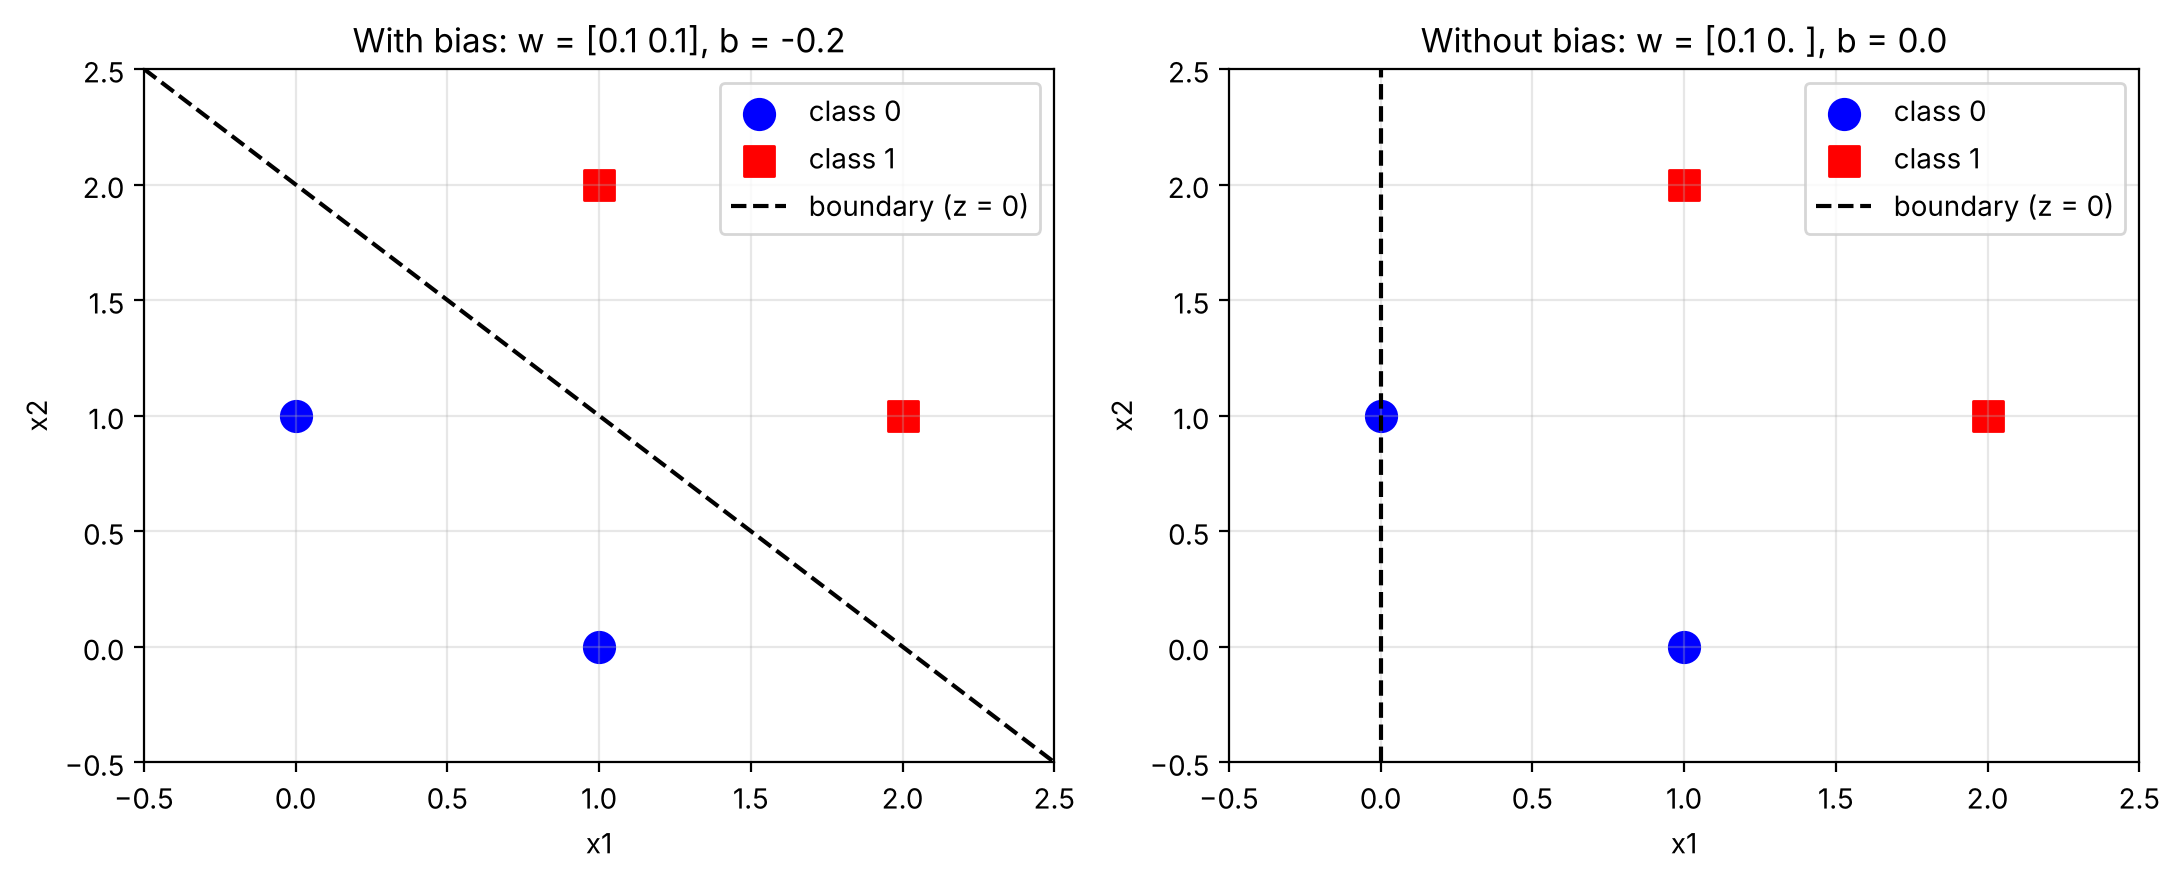

In [ ]:
# task 3.2:
def train_perceptron_no_bias(X, y, eta=0.1, max_epochs=100):
    w = np.zeros(X.shape[1])
    b = 0.0                            
    history = []
    for ep in range(max_epochs):
        wrong = 0
        for xi, target in zip(X, y):
            err = target - predict(w, xi, b)
            if err != 0:
                w += eta * err * xi
                wrong += 1
        history.append(wrong)
        if wrong == 0:
            break
    return w, b, history

X_b = np.array([[1, 0], [0, 1], [2, 1], [1, 2]])
y_b = np.array([0, 0, 1, 1])

w_bias, b_bias, h_bias = train_perceptron(X_b, y_b)
w_nob, b_nob, h_nob = train_perceptron_no_bias(X_b, y_b)

print(f"with bias    -> w = {w_bias}, b = {b_bias:.1f}, epochs = {len(h_bias)}, mistakes in last epoch = {h_bias[-1]}")
print(f"without bias -> w = {w_nob}, b = {b_nob:.1f}, epochs = {len(h_nob)}, mistakes in last epoch = {h_nob[-1]}")

grid = np.linspace(-0.5, 2.5, 100)
plt.figure(figsize=(11, 4.5))
for k, (w, b, name) in enumerate([(w_bias, b_bias, "With bias"), (w_nob, b_nob, "Without bias")], start=1):
    ax = plt.subplot(1, 2, k)
    scatter_classes(ax, X_b, y_b)
    plot_boundary(ax, w, b, x1=grid)
    ax.set(xlim=(-0.5, 2.5), ylim=(-0.5, 2.5), xlabel="x1", ylabel="x2",
           title=f"{name}: w = {w}, b = {b:.1f}")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** With bias it converged in 4 epochs to x₁ + x₂ = 2, which sits right between the class-0 points (sum = 1) and the class-1 points (sum = 3). Without bias it never converged and was still making mistakes after 100 epochs, ending with a vertical line at x₁ = 0. Without b the line has to go through the origin, and no line through (0, 0) can split these points: making (1,0) and (0,1) negative needs both weights < 0, which would make (2,1) and (1,2) negative too. So the weights only rotate the line, and the bias is what lets it shift.

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

epochs run              : 100
mistakes (first 8 eps)  : [3, 3, 4, 4, 4, 4, 4, 4]
mistakes in last epoch  : 4
final w, b              : [-0.1  0. ] 0.0
predictions with final w: [1, 1, 0, 0]   true labels: [0, 1, 1, 0]


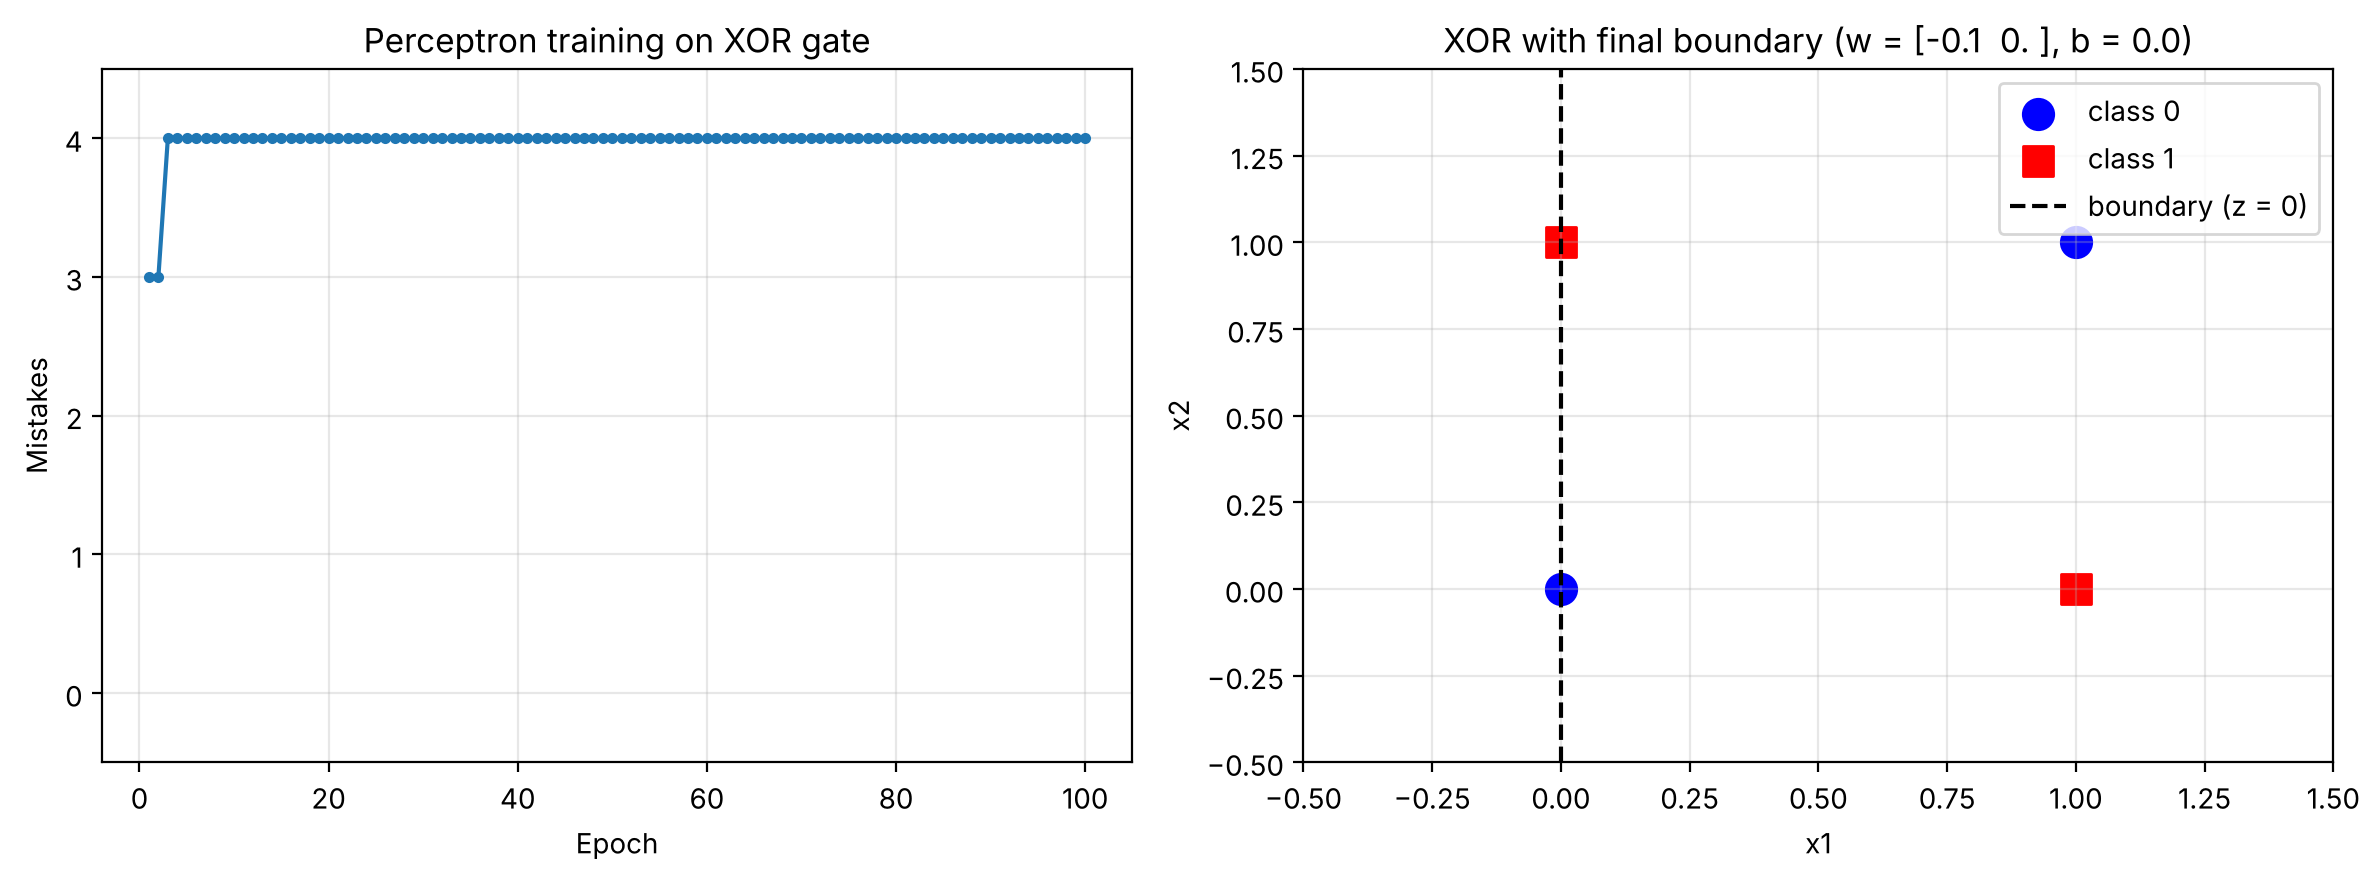

In [ ]:
# Task 4.1: 
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

w_xor, b_xor, h_xor = train_perceptron(X_xor, y_xor, max_epochs=100)
final_pred = [predict(w_xor, x, b_xor) for x in X_xor]

print("epochs run              :", len(h_xor))
print("mistakes (first 8 eps)  :", h_xor[:8])
print("mistakes in last epoch  :", h_xor[-1])
print("final w, b              :", w_xor, round(b_xor, 2))
print("predictions with final w:", final_pred, "  true labels:", y_xor.tolist())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(np.arange(1, len(h_xor) + 1), h_xor, '.-')
ax1.set(title="Perceptron training on XOR gate", xlabel="Epoch", ylabel="Mistakes", ylim=(-0.5, 4.5))
ax1.grid(True, alpha=0.3)

scatter_classes(ax2, X_xor, y_xor)
plot_boundary(ax2, w_xor, b_xor)
ax2.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xlabel="x1", ylabel="x2",
        title=f"XOR with final boundary (w = {w_xor}, b = {b_xor:.1f})")
ax2.grid(True, alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.show()

**Interpretation:** It never gets to zero mistakes. After the first two epochs it is stuck at 4 mistakes every epoch for all 100 epochs, and the final line (vertical at x₁ = 0) still gets (0, 0) and (1, 0) wrong. The reason is that XOR is not linearly separable: the 1s are on one diagonal and the 0s on the other, so whatever single line it tries, at least one point ends up on the wrong side and it just keeps cycling.

(The last epoch says 4 mistakes while the final weights only miss 2 points, because mistakes are counted while the weights are still changing inside the epoch.)

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [ ]:
# Task 4.2: 
def check_xor(w, b):
    z00 = np.dot(w, [0, 0]) + b
    z01 = np.dot(w, [0, 1]) + b
    z10 = np.dot(w, [1, 0]) + b
    z11 = np.dot(w, [1, 1]) + b
    return z00 < 0 and z01 >= 0 and z10 >= 0 and z11 < 0

np.random.seed(RS)
W_try = np.random.uniform(-5, 5, (10000, 2))
b_try = np.random.uniform(-5, 5, 10000)

hits = [i for i in range(len(b_try)) if check_xor(W_try[i], b_try[i])]
print("random triples tested :", len(b_try))
print("triples that work     :", len(hits))
print("No solution found" if not hits else f"First passing triple: w = {W_try[hits[0]]}, b = {b_try[hits[0]]}")

# extra: how close did the random triples get?
n_ok = [int(b_try[i] < 0) + int(W_try[i, 1] + b_try[i] >= 0) +
        int(W_try[i, 0] + b_try[i] >= 0) + int(W_try[i].sum() + b_try[i] < 0) for i in range(10000)]
print("number of triples meeting 0/1/2/3/4 conditions:", np.bincount(n_ok, minlength=5))

random triples tested : 10000
triples that work     : 0
No solution found
number of triples meeting 0/1/2/3/4 conditions: [   0 1500 7073 1427    0]


**Interpretation:** Out of 10,000 random (w₁, w₂, b) triples, not one satisfies all four XOR conditions, so "No solution found" is printed. The best any triple managed was 3 out of 4 (1,427 of them), which shows the conditions clash with each other. The random test is only evidence, but it agrees with the algebra in Q3(a).

## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [ ]:
# Task 5.1: 
X_p = iris.data[:, (2, 3)]                  
y_p = (iris.target == 0).astype(int)       

Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_p, y_p, test_size=0.3, random_state=RS, stratify=y_p)

per = Perceptron(random_state=RS)
per.fit(Xp_train, yp_train)
yp_pred = per.predict(Xp_test)

print("Accuracy:", round(accuracy_score(yp_test, yp_pred), 3))
print("\nConfusion matrix:")
print(confusion_matrix(yp_test, yp_pred))
print("\nClassification report:")
print(classification_report(yp_test, yp_pred, target_names=['not setosa', 'setosa']))
print("coef_      (= w):", per.coef_)
print("intercept_ (= b):", per.intercept_)
print("epochs (n_iter_):", per.n_iter_)

Accuracy: 1.0

Confusion matrix:
[[30  0]
 [ 0 15]]

Classification report:
              precision    recall  f1-score   support

  not setosa       1.00      1.00      1.00        30
      setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_      (= w): [[-1.3 -2.2]]
intercept_ (= b): [4.]
epochs (n_iter_): 7


**Interpretation:** Accuracy is 1.0 and the confusion matrix has no errors (30 non-setosa and 15 setosa all correct). `coef_` = [−1.3, −2.2] is the weight vector **w** and `intercept_` = 4 is the bias **b** from Part 1. Both weights are negative, meaning the bigger the petal, the lower z gets, which makes sense because setosa has the smallest petals.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

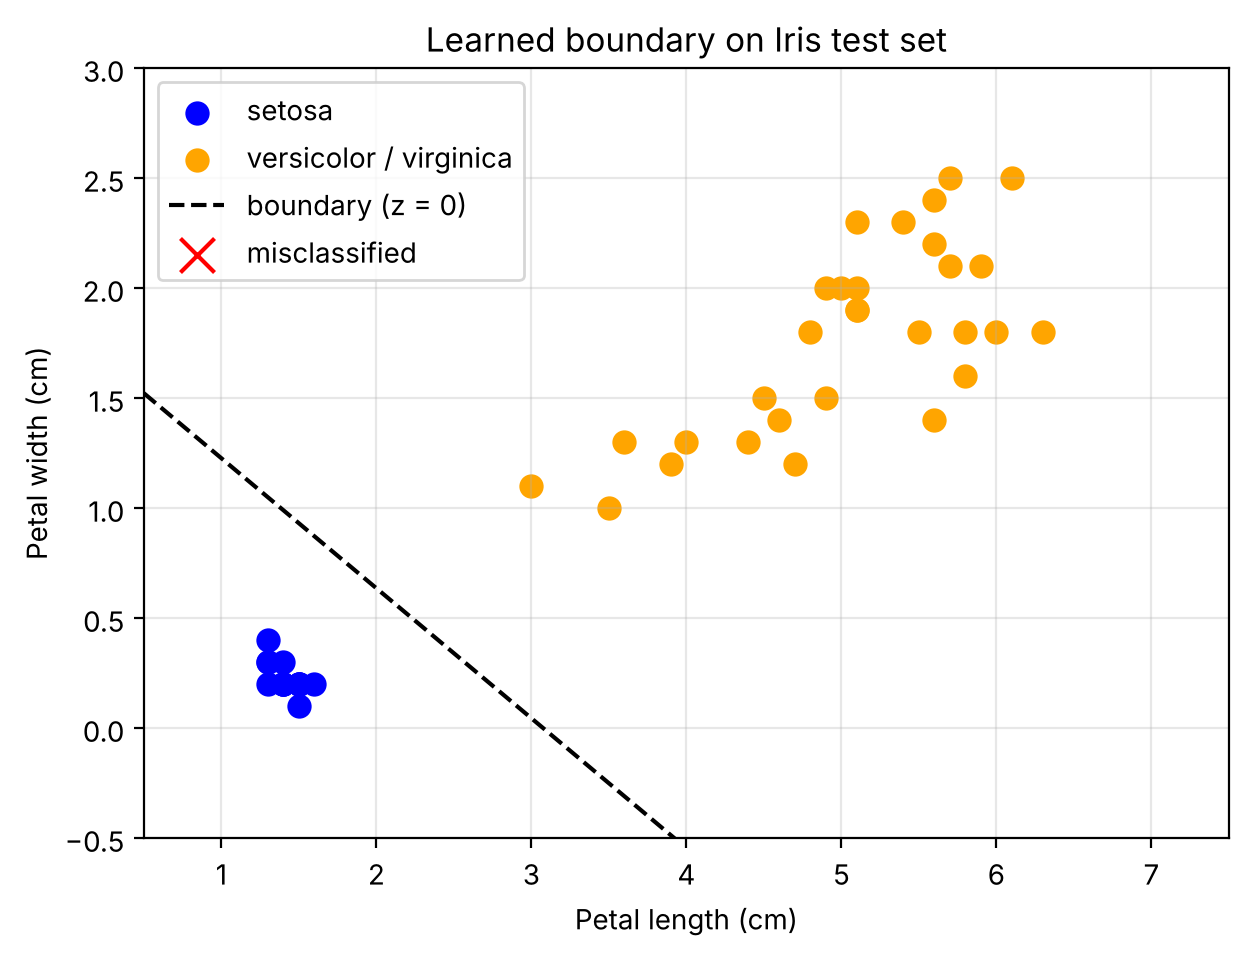

Number of misclassified test points: 0


In [ ]:
# Task 5.2:
w_p, b_p = per.coef_[0], per.intercept_[0]
wrong_mask = yp_pred != yp_test

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(Xp_test[yp_test == 1, 0], Xp_test[yp_test == 1, 1], color='blue', s=60, label='setosa')
ax.scatter(Xp_test[yp_test == 0, 0], Xp_test[yp_test == 0, 1], color='orange', s=60, label='versicolor / virginica')
plot_boundary(ax, w_p, b_p, x1=np.linspace(0.5, 7.5, 100))
ax.scatter(Xp_test[wrong_mask, 0], Xp_test[wrong_mask, 1], color='red', marker='x', s=150, label='misclassified')
ax.set(xlim=(0.5, 7.5), ylim=(-0.5, 3), xlabel="Petal length (cm)", ylabel="Petal width (cm)",
       title="Learned boundary on Iris test set")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

print("Number of misclassified test points:", wrong_mask.sum())

**Interpretation:** No test point is misclassified (0 red ×), and the boundary is a straight line (about x₂ = −0.59x₁ + 1.82), as it always is for a perceptron. The small setosa group in the bottom-left is far from the other flowers, but the line is drawn closer to the setosa side than the middle of the gap, because the perceptron stops as soon as everything in training is correct and doesn't look for the safest line.

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [ ]:
# Task 5.3: 
preds_by_eta = {}
print(f"{'eta0':>7} | {'accuracy':>8} | {'n_iter_':>7} | coef_                | intercept_")
print("-" * 64)
for eta in [0.001, 0.1, 10.0]:
    model = Perceptron(eta0=eta, random_state=RS).fit(Xp_train, yp_train)
    preds_by_eta[eta] = model.predict(Xp_test)
    print(f"{eta:>7} | {accuracy_score(yp_test, preds_by_eta[eta]):>8.3f} | {model.n_iter_:>7} | "
          f"{str(np.round(model.coef_[0], 4)):<20} | {model.intercept_[0]}")

same = all(np.array_equal(preds_by_eta[0.001], preds_by_eta[e]) for e in [0.1, 10.0])
print("\nAre the predictions identical for all three eta0 values?", same)

   eta0 | accuracy | n_iter_ | coef_                | intercept_
----------------------------------------------------------------
  0.001 |    1.000 |       6 | [-0.0013 -0.0022]    | 0.004
    0.1 |    1.000 |       7 | [-0.13 -0.22]        | 0.4
   10.0 |    1.000 |       7 | [-13. -22.]          | 40.0

Are the predictions identical for all three eta0 values? True


**Interpretation:** Changing the learning rate does not change any prediction; all three give accuracy 1.0. The coef_ values are just scaled versions of each other (−0.0013, −0.13, −13 for the first weight), and the intercept scales the same way. Because training starts at w = 0, every update is η times the same thing, so η only multiplies w and b by a constant. Multiplying the whole equation by a positive number gives the same line, so the decisions stay the same. (n_iter_ is 6 instead of 7 for η = 0.001 only because sklearn's stopping tolerance is reached sooner when the numbers are tiny.)

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [ ]:
# Task 6.1:
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=RS, stratify=iris.target)

per_multi = Perceptron(random_state=RS, max_iter=1000)
per_multi.fit(Xa_train, ya_train)
ya_pred_per = per_multi.predict(Xa_test)

print(classification_report(ya_test, ya_pred_per, target_names=iris.target_names, zero_division=0))
print("Confusion matrix (rows = true, cols = predicted):")
print(confusion_matrix(ya_test, ya_pred_per))
print("\ncoef_.shape =", per_multi.coef_.shape)
print("coef_ =\n", np.round(per_multi.coef_, 2))
print("intercept_ =", per_multi.intercept_)

              precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix (rows = true, cols = predicted):
[[15  0  0]
 [14  0  1]
 [ 0  0 15]]

coef_.shape = (3, 4)
coef_ =
 [[  2.1   7.3  -9.9  -4.5]
 [  4.5 -29.1   6.7 -14.7]
 [-35.5 -25.1  46.2  45.7]]
intercept_ = [  1.   6. -22.]


**Interpretation:** `coef_` has shape (3, 4), so there are 3 perceptrons (one-vs-rest, one per species) and each one has 4 weights, one per feature. Row 0 decides setosa vs the rest, row 1 versicolor vs the rest and row 2 virginica vs the rest, and the class with the highest score wins. Accuracy is only 0.67 (macro-F1 0.55).

The hardest class is **versicolor**: it has 0 correct out of 15. The confusion matrix shows 14 versicolor predicted as setosa and 1 as virginica, while setosa and virginica are 15/15 each. Versicolor lies in the middle, between small setosa and large virginica, so "versicolor vs rest" can't be split by one straight line. Its perceptron never trains properly, and the other classes always win.

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [ ]:
# Task 6.2: 
logreg = LogisticRegression(random_state=RS, max_iter=200)
logreg.fit(Xa_train, ya_train)
ya_pred_lr = logreg.predict(Xa_test)

summary = [("Perceptron", ya_pred_per), ("Logistic Regression", ya_pred_lr)]
print(f"{'Model':<21} | {'Accuracy':>8} | {'Macro-F1':>8}")
print("-" * 43)
for name, p in summary:
    print(f"{name:<21} | {accuracy_score(ya_test, p):>8.3f} | {f1_score(ya_test, p, average='macro'):>8.3f}")

print("\nLogistic Regression confusion matrix:")
print(confusion_matrix(ya_test, ya_pred_lr))

Model                 | Accuracy | Macro-F1
-------------------------------------------
Perceptron            |    0.667 |    0.550
Logistic Regression   |    0.933 |    0.933

Logistic Regression confusion matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  2 13]]


**Interpretation:** Logistic regression is much better on the same split: 0.933 accuracy and 0.933 macro-F1, compared with 0.667 and 0.550 for the perceptron. It gets 14/15 versicolor right, and its only 3 errors are versicolor/virginica mix-ups, which is expected since those two overlap a bit.

This is because the step function only tells the perceptron right or wrong, so on a class that can't be separated it keeps flipping and stops wherever it ends up. The sigmoid in logistic regression is smooth and its gradient never becomes exactly zero, so every point keeps giving feedback on how far off it is, and the model settles on the line with the lowest overall error.

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

**Given:** w₁ = 0.5, w₂ = −0.3, b = 0.2, η = 0.1, x = [1, 2], y = 0

**1. Net input**
z = w₁x₁ + w₂x₂ + b = (0.5)(1) + (−0.3)(2) + 0.2 = 0.5 − 0.6 + 0.2 = **0.1**

**2. Output**
z = 0.1 ≥ 0, so **ŷ = 1**

**3. Error**
e = y − ŷ = 0 − 1 = **−1** → the prediction is wrong, so we update.

**4. Updates** (wᵢ ← wᵢ + η·e·xᵢ, b ← b + η·e)
- w₁ = 0.5 + (0.1)(−1)(1) = 0.5 − 0.1 = **0.4**
- w₂ = −0.3 + (0.1)(−1)(2) = −0.3 − 0.2 = **−0.5**
- b = 0.2 + (0.1)(−1) = **0.1**

**Check:** new z = (0.4)(1) + (−0.5)(2) + 0.1 = −0.5 < 0 → ŷ = 0 = y, so the update fixed this example.

**Answer:** z = 0.1, ŷ = 1, e = −1, new w = [0.4, −0.5], new b = 0.1. w₂ moved twice as much as w₁ because x₂ = 2 is twice x₁.

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

**Given:** w = [0.3, 0.2], b = −0.4

**Boundary (z = 0):**
0.3x₁ + 0.2x₂ − 0.4 = 0
→ 0.2x₂ = −0.3x₁ + 0.4
→ **x₂ = −1.5x₁ + 2**

(slope −1.5; it cuts the x₂-axis at 2 and the x₁-axis at about 1.33)

**Point (1, 1):**
z = 0.3(1) + 0.2(1) − 0.4 = **0.1 ≥ 0 → ŷ = 1**

On the line, at x₁ = 1 we get x₂ = 0.5. The point has x₂ = 1 > 0.5, so **(1, 1) is above the line, on the ŷ = 1 side**.

**Check with all AND inputs:**

| x₁ | x₂ | z | ŷ | AND |
|---|---|---|---|---|
| 0 | 0 | −0.4 | 0 | 0 ✓ |
| 0 | 1 | −0.2 | 0 | 0 ✓ |
| 1 | 0 | −0.1 | 0 | 0 ✓ |
| 1 | 1 | 0.1 | 1 | 1 ✓ |

So these weights do implement AND, with only (1, 1) on the positive side.

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

### (a) Algebra

ŷ = 1 needs z ≥ 0 and ŷ = 0 needs z < 0. Writing z = w₁x₁ + w₂x₂ + b for each XOR row:

| x₁ | x₂ | y | z | needs |
|---|---|---|---|---|
| 0 | 0 | 0 | b | (i) b < 0 |
| 0 | 1 | 1 | w₂ + b | (ii) w₂ + b ≥ 0 |
| 1 | 0 | 1 | w₁ + b | (iii) w₁ + b ≥ 0 |
| 1 | 1 | 0 | w₁ + w₂ + b | (iv) w₁ + w₂ + b < 0 |

Adding (ii) and (iii): w₁ + w₂ + 2b ≥ 0, so w₁ + w₂ + b ≥ −b.

From (i), b is negative, so −b is positive. That means w₁ + w₂ + b ≥ −b > 0, i.e. **w₁ + w₂ + b > 0**.

But (iv) says w₁ + w₂ + b < 0. Both can't be true, so there are no w₁, w₂, b that satisfy all four conditions, and **one perceptron cannot learn XOR**. ∎
In simple words: if x₁ alone and x₂ alone are each enough to make z positive, then both together must also make it positive, but XOR needs it to be negative.

### (b) Sketch

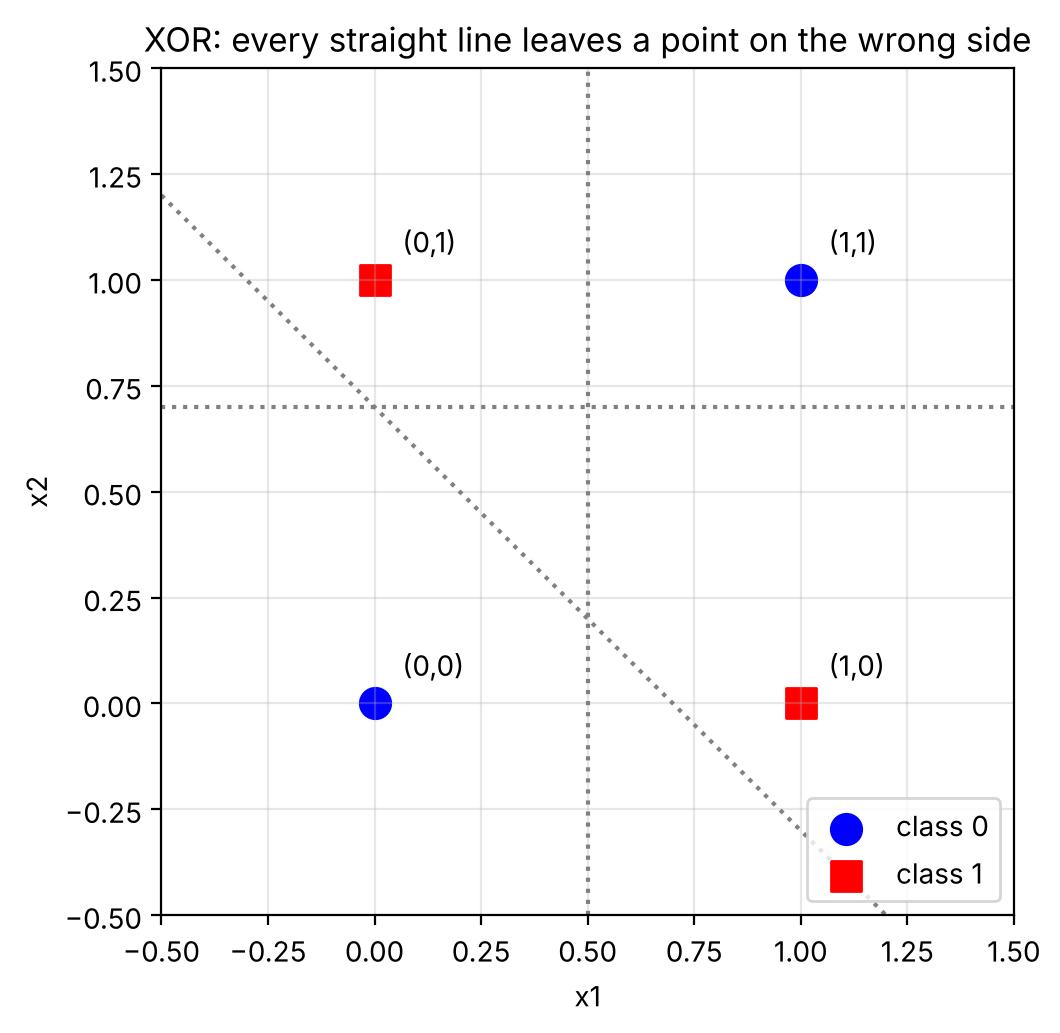

In [ ]:

fig, ax = plt.subplots(figsize=(5.5, 5.5))
scatter_classes(ax, X_xor, y_xor)
for (x0, y0, x1_, y1_) in [(-0.5, 0.7, 1.5, 0.7), (-0.5, 1.2, 1.2, -0.5), (0.5, -0.5, 0.5, 1.5)]:
    ax.plot([x0, x1_], [y0, y1_], linestyle=':', color='gray')
for (px, py) in X_xor:
    ax.annotate(f"({px},{py})", (px, py), textcoords="offset points", xytext=(10, 10))
ax.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xlabel="x1", ylabel="x2",
       title="XOR: every straight line leaves a point on the wrong side")
ax.grid(True, alpha=0.3)
ax.legend(loc='lower right')
plt.show()

The 1s, (0,1) and (1,0), are on one diagonal and the 0s, (0,0) and (1,1), are on the other, like a checkerboard. The grey dotted lines are three tries (horizontal, diagonal, vertical), and each one leaves at least one point on the wrong side. Since the two class-1 points are at opposite corners, any line that keeps them together also catches a class-0 point, so XOR is **not linearly separable**.

### (c) Fix

Use a **hidden layer**, i.e. a **multi-layer perceptron (MLP)**. For example, XOR = AND(OR(x₁, x₂), NAND(x₁, x₂)):

- hidden h₁ = OR: w = [1, 1], b = −0.5
- hidden h₂ = NAND: w = [−1, −1], b = 1.5
- output = AND(h₁, h₂): w = [1, 1], b = −1.5

| x₁ | x₂ | h₁ | h₂ | h₁ + h₂ − 1.5 | ŷ |
|---|---|---|---|---|---|
| 0 | 0 | 0 | 1 | −0.5 | 0 |
| 0 | 1 | 1 | 1 | 0.5 | 1 |
| 1 | 0 | 1 | 1 | 0.5 | 1 |
| 1 | 1 | 1 | 0 | −0.5 | 0 |

Each hidden neuron draws its own line, and the output fires only for points between the two lines, which is exactly the XOR region.

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [ ]:
# Q4: 
y_set = (iris.target == 0).astype(int)
q4_rows = []
for feats, label in [((2, 3), "petal L, petal W"), ((0, 2, 3), "sepal L, petal L, petal W")]:
    Xq = iris.data[:, feats]
    Xq_tr, Xq_te, yq_tr, yq_te = train_test_split(Xq, y_set, test_size=0.3, random_state=RS, stratify=y_set)
    mdl = Perceptron(random_state=RS).fit(Xq_tr, yq_tr)
    pq = mdl.predict(Xq_te)
    print(f"[{label}] confusion matrix:\n{confusion_matrix(yq_te, pq)}\n")
    q4_rows.append([label, accuracy_score(yq_te, pq), f1_score(yq_te, pq, average='macro'),
                    mdl.n_iter_, np.round(mdl.coef_[0], 2), mdl.intercept_[0]])

print(f"{'features':<26} | {'acc':>5} | {'macro-F1':>8} | {'epochs':>6} | coef_            | b")
print("-" * 80)
for label, a, f, n, c, b in q4_rows:
    print(f"{label:<26} | {a:>5.3f} | {f:>8.3f} | {n:>6} | {str(c):<16} | {b}")

[petal L, petal W] confusion matrix:
[[30  0]
 [ 0 15]]

[sepal L, petal L, petal W] confusion matrix:
[[30  0]
 [ 0 15]]

features                   |   acc | macro-F1 | epochs | coef_            | b
--------------------------------------------------------------------------------
petal L, petal W           | 1.000 |    1.000 |      7 | [-1.3 -2.2]      | 4.0
sepal L, petal L, petal W  | 1.000 |    1.000 |      7 | [ 4.5 -8.7 -4.1] | 2.0


**Answer:** Using features (0, 2, 3) gives **accuracy = 1.000 and macro-F1 = 1.000**, which is the same as the Part 5 model with only the two petal features (also 1.000 and 1.000, both with confusion matrix [[30, 0], [0, 15]] and 7 epochs). So **the extra feature does not help here.**

Setosa vs the rest was already perfectly separable from petal size alone (in the training set the biggest setosa petal length is 1.9 cm and the smallest non-setosa is 3.3 cm), so 100% can't get any higher. Adding sepal length just gives different weights, w = [4.5, −8.7, −4.1] and b = 2.0, and turns the line into a plane in 3-D, but the predictions are exactly the same. The two petal weights are still the biggest (in absolute value), so the petals are still doing most of the work. An extra feature would only be worth it if the current ones couldn't separate the classes.

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

model        | test acc | epochs | w                  | b
------------------------------------------------------------
my version   |    0.817 |    100 | [ 0.307 -0.256]    | 0.20
sklearn      |    0.667 |      6 | [2.281 0.58 ]      | 2.00

my version, mistakes in the last 5 epochs: [30, 32, 32, 33, 33] | lowest in any epoch: 29


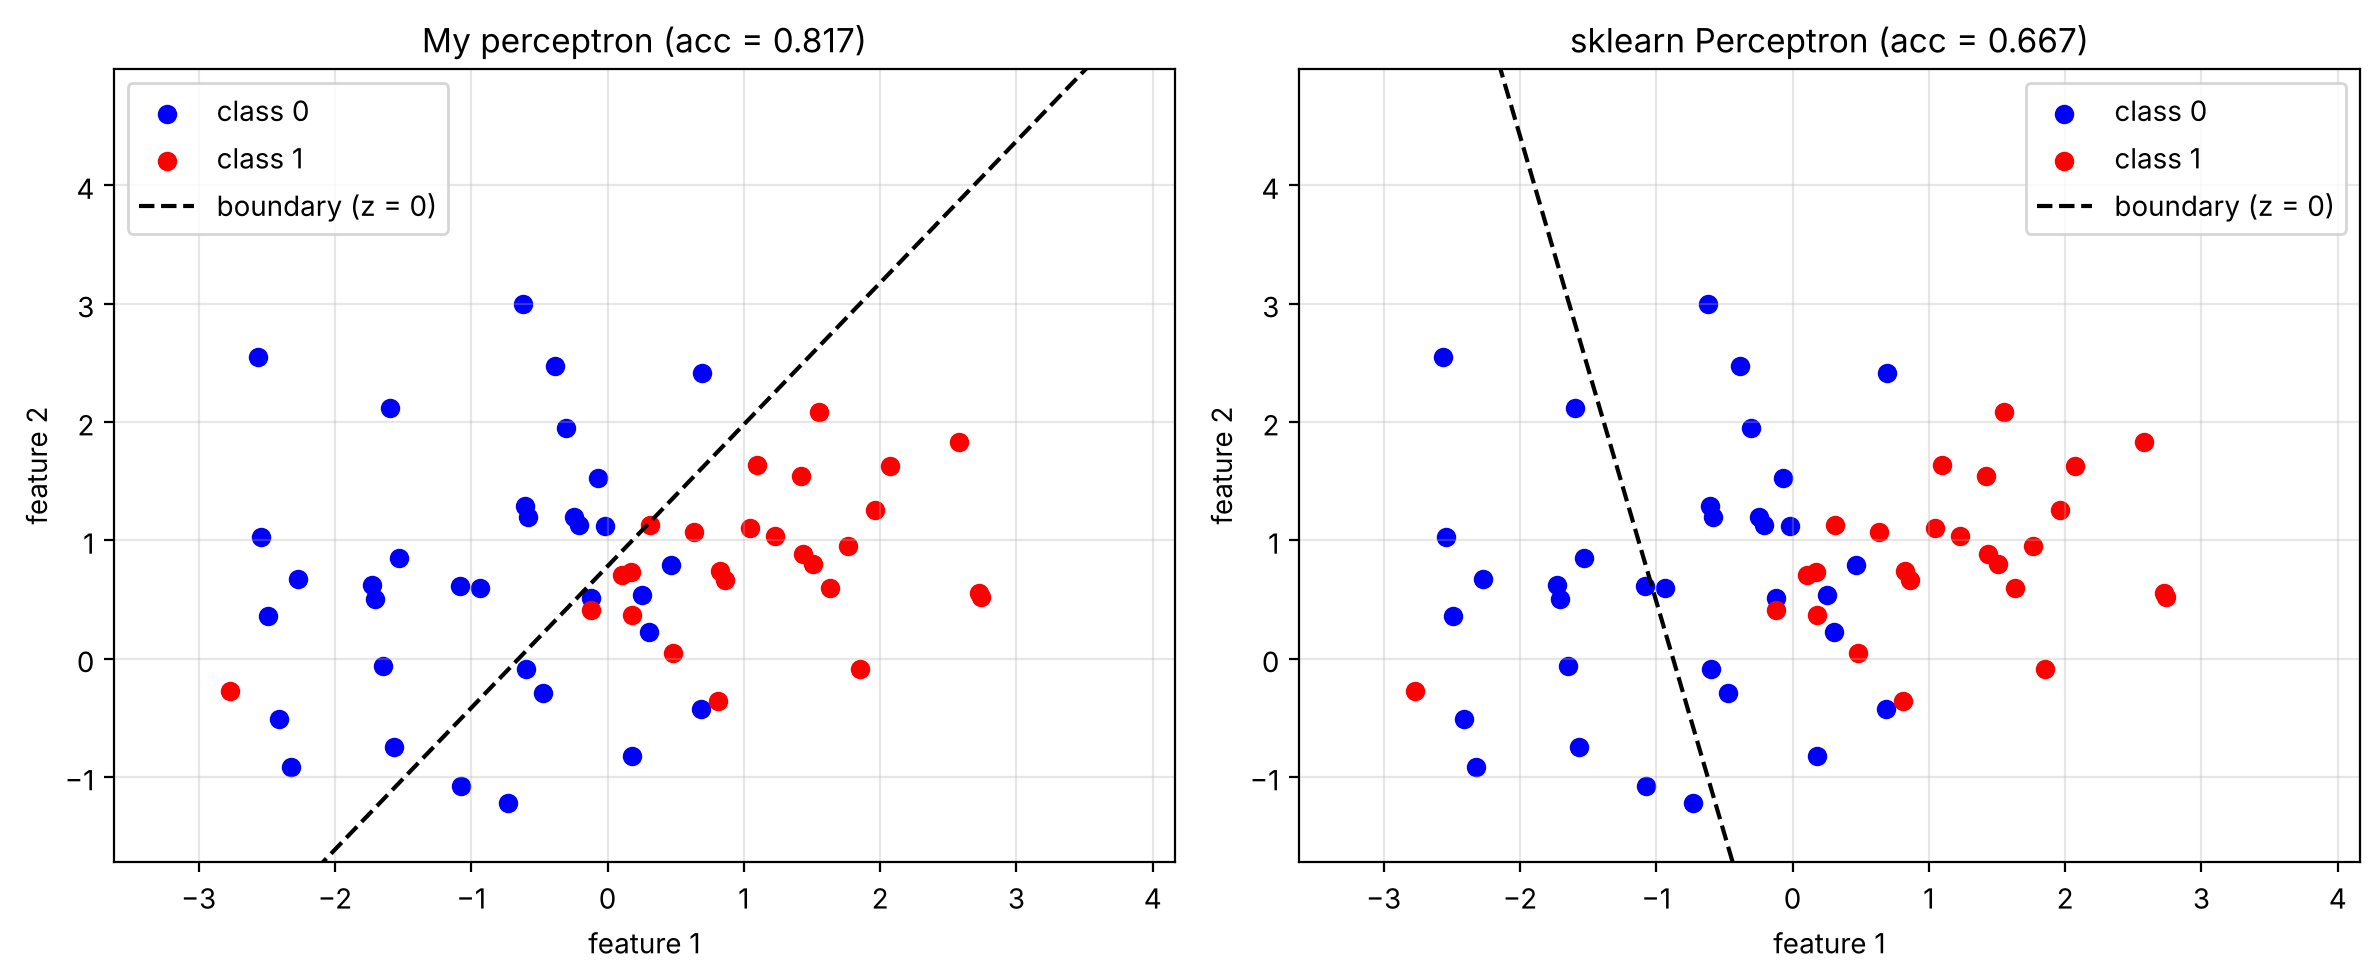

In [ ]:
# Q5: 
X_syn, y_syn = make_classification(n_samples=200, n_features=2, n_redundant=0,
                                   n_clusters_per_class=1, random_state=RS)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(X_syn, y_syn, test_size=0.3, random_state=RS)

# my own perceptron from Part 2
w_mine, b_mine, h_mine = train_perceptron(Xs_tr, ys_tr, eta=0.1, max_epochs=100)
pred_mine = np.array([predict(w_mine, x, b_mine) for x in Xs_te])
acc_mine = accuracy_score(ys_te, pred_mine)

# sklearn perceptron
skp = Perceptron(random_state=RS).fit(Xs_tr, ys_tr)
pred_skp = skp.predict(Xs_te)
acc_skp = accuracy_score(ys_te, pred_skp)

print(f"{'model':<12} | {'test acc':>8} | {'epochs':>6} | {'w':<18} | b")
print("-" * 60)
print(f"{'my version':<12} | {acc_mine:>8.3f} | {len(h_mine):>6} | {str(np.round(w_mine, 3)):<18} | {b_mine:.2f}")
print(f"{'sklearn':<12} | {acc_skp:>8.3f} | {skp.n_iter_:>6} | {str(np.round(skp.coef_[0], 3)):<18} | {skp.intercept_[0]:.2f}")
print("\nmy version, mistakes in the last 5 epochs:", h_mine[-5:], "| lowest in any epoch:", min(h_mine))

xs_line = np.linspace(X_syn[:, 0].min() - 0.5, X_syn[:, 0].max() + 0.5, 100)
plt.figure(figsize=(12, 5))
for k, (w, b, name) in enumerate([(w_mine, b_mine, f"My perceptron (acc = {acc_mine:.3f})"),
                                  (skp.coef_[0], skp.intercept_[0], f"sklearn Perceptron (acc = {acc_skp:.3f})")], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(Xs_te[ys_te == 0, 0], Xs_te[ys_te == 0, 1], color='blue', label='class 0')
    ax.scatter(Xs_te[ys_te == 1, 0], Xs_te[ys_te == 1, 1], color='red', label='class 1')
    plot_boundary(ax, w, b, x1=xs_line)
    ax.set(xlim=(xs_line.min(), xs_line.max()), ylim=(X_syn[:, 1].min() - 0.5, X_syn[:, 1].max() + 0.5),
           xlabel="feature 1", ylabel="feature 2", title=name)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Answer:**

| | my perceptron | sklearn |
|---|---|---|
| test accuracy | 0.817 | 0.667 |
| epochs | 100 (never converged) | 6 (stopped early) |
| final w | [0.307, −0.256] | [2.281, 0.580] |
| final b | 0.20 | 2.00 |

My perceptron did better on the test set (81.7% vs 66.7%). It used all 100 epochs and never got to zero mistakes (still 29–33 per epoch at the end), because the two classes overlap and this data is **not linearly separable**. sklearn stopped after only 6 epochs because of its early stopping (it quits when the loss hasn't improved by more than `tol` for 5 epochs in a row), and it also shuffles the data each epoch.

Because neither model can actually converge, the final w and b are basically just wherever training stopped, which is why they look so different. In the plots, my line is a diagonal that goes through the middle of the overlap, while sklearn's line is steep and far to the left, so a big part of the blue class ends up on the red side, which explains its lower accuracy. Both boundaries are still straight lines. Overall, on overlapping data the perceptron's result depends a lot on luck and on when it stops, which is a good reason to use something like logistic regression instead.